# Technique-Specific Augmentation Demo

Applies per-technique acoustic transformations to **Control_Group** utterances from GTSinger
using the WORLD vocoder. For each of the 5 expressive techniques, one representative word
is augmented, the result is plotted (F0 + spectrogram) and saved, and the JSON label is
updated to reflect which phonemes now carry the technique.

**Techniques covered:** Vibrato · Breathy · Glissando · Pharyngeal · Mixed/Falsetto

**Reference pipeline:** Zhang et al. (2021) PDAugment — pitch and duration adjustments
guided by note information — adapted here to use GTSinger's per-phoneme JSON annotations
instead of external MIDI scores.

In [1]:
import json
import copy
import os
import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pyworld as pw
from IPython.display import Audio, display
import warnings
warnings.filterwarnings('ignore')

REPO   = '/home/antonello/Desktop/thesis-alt-expressive'
DATA   = os.path.join(REPO, 'data/GTSinger/English')
OUT    = os.path.join(REPO, 'results/augmentation_demo')
FRAME_MS = 5.0   # WORLD frame period in milliseconds
SR = 16000

VOWELS = {
    'AA','AE','AH','AO','AW','AY','EH','ER','EY',
    'IH','IY','OW','OY','UH','UW'
}

# Technique index used in the 'tech' field of GTSinger JSON
TECH_CODE = {
    'mix': '1', 'falsetto': '2', 'breathy': '3',
    'pharyngeal': '4', 'glissando': '5', 'vibrato': '6'
}

print('Imports OK')

Imports OK


/home/antonello/miniforge3/envs/thesis-alt/lib/python3.11/site-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
# ─── Shared helpers ───────────────────────────────────────────────────────────

def load_utterance(wav_path, json_path):
    wav, sr = sf.read(wav_path)
    if wav.ndim == 2:
        wav = wav.mean(axis=1)
    wav = wav.astype(np.float64)
    if sr != SR:
        wav = librosa.resample(wav.astype(np.float32), orig_sr=sr, target_sr=SR).astype(np.float64)
    with open(json_path) as f:
        meta = json.load(f)
    return wav, SR, meta


def world_decompose(wav, sr=SR):
    f0, sp, ap = pw.wav2world(wav, sr, frame_period=FRAME_MS)
    return f0, sp, ap


def world_synthesize(f0, sp, ap, sr=SR):
    return pw.synthesize(f0, sp, ap, sr, frame_period=FRAME_MS)


def t2f(t_sec):
    """Seconds → WORLD frame index."""
    return int(round(t_sec * 1000.0 / FRAME_MS))


def midi_to_hz(midi):
    """MIDI note number → frequency in Hz."""
    return 440.0 * (2.0 ** ((midi - 69) / 12.0))


def find_word(meta, word_str):
    """Return (index, entry) for the first matching word in the JSON."""
    for i, w in enumerate(meta):
        if w['word'].lower() == word_str.lower():
            return i, w
    raise KeyError(f'Word "{word_str}" not found in utterance')


def get_vowel_spans(word_entry):
    """Return list of (ph, start_s, end_s) for vowel phonemes in a word."""
    spans = []
    for ph, ps, pe in zip(word_entry['ph'], word_entry['ph_start'], word_entry['ph_end']):
        if ph.rstrip('012') in VOWELS:
            spans.append((ph, float(ps), float(pe)))
    return spans


def update_labels(meta, word_idx, technique_key):
    """Return a deep-copied meta with technique flag flipped on all phonemes of word_idx."""
    aug_meta = copy.deepcopy(meta)
    w = aug_meta[word_idx]
    n = len(w['ph'])
    w[technique_key] = ['1'] * n
    # Update tech string (comma-separated technique codes)
    existing = set(w['tech'].split(',')) if w['tech'] != '0' else set()
    existing.discard('0')
    existing.add(TECH_CODE[technique_key])
    w['tech'] = ','.join(sorted(existing, key=int))
    return aug_meta


def save_result(out_dir, tag, wav_aug, meta_aug, sr=SR):
    os.makedirs(out_dir, exist_ok=True)
    wav_path  = os.path.join(out_dir, f'{tag}.wav')
    json_path = os.path.join(out_dir, f'{tag}.json')
    sf.write(wav_path,  wav_aug, sr)
    with open(json_path, 'w') as f:
        json.dump(meta_aug, f, indent=2)
    print(f'Saved → {wav_path}')
    return wav_path


def plot_comparison(wav_orig, wav_aug, f0_orig, f0_aug, sr,
                    mark_start, mark_end, title, technique_label):
    """
    4-panel figure: original spectrogram + F0 | augmented spectrogram + F0.
    Vertical dashed lines indicate the modified region.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 6),
                             gridspec_kw={'height_ratios': [3, 1]})
    fig.suptitle(title, fontsize=13, fontweight='bold')

    for col, (wav, f0, label) in enumerate([
            (wav_orig, f0_orig, 'Original (Control)'),
            (wav_aug,  f0_aug,  f'Augmented ({technique_label})')
    ]):
        # Spectrogram
        ax_s = axes[0][col]
        D = librosa.amplitude_to_db(
            np.abs(librosa.stft(wav.astype(np.float32), n_fft=512, hop_length=80)),
            ref=np.max)
        librosa.display.specshow(D, sr=sr, hop_length=80, x_axis='time',
                                 y_axis='hz', ax=ax_s, cmap='magma')
        ax_s.set_ylim(0, 2000)
        ax_s.set_title(label)
        ax_s.axvline(mark_start, color='cyan', lw=1.5, ls='--', label='target phoneme')
        ax_s.axvline(mark_end,   color='cyan', lw=1.5, ls='--')
        ax_s.legend(fontsize=8, loc='upper right')

        # F0 contour
        ax_f = axes[1][col]
        times_f0 = np.arange(len(f0)) * (FRAME_MS / 1000)
        voiced   = f0 > 0
        ax_f.plot(times_f0[voiced], f0[voiced], color='lime', lw=1.5)
        ax_f.set_ylabel('F0 (Hz)')
        ax_f.set_xlabel('Time (s)')
        ax_f.set_xlim(0, len(wav) / sr)
        ax_f.axvline(mark_start, color='cyan', lw=1.5, ls='--')
        ax_f.axvline(mark_end,   color='cyan', lw=1.5, ls='--')
        ax_f.set_ylim(50, 900)

    plt.tight_layout()
    plt.show()


def show_json_diff(orig_word, aug_word, technique_key):
    print(f'\n── JSON diff for "{orig_word["word"]}" (technique: {technique_key}) ──')
    print(f'  tech:        {orig_word["tech"]}  →  {aug_word["tech"]}')
    orig_flags = orig_word[technique_key]
    aug_flags  = aug_word[technique_key]
    print(f'  {technique_key}: {orig_flags}  →  {aug_flags}')
    print(f'  phonemes:   {aug_word["ph"]}')


print('Helpers defined')

Helpers defined


---
## 1. Vibrato

**Acoustic description.** Vibrato is a quasi-periodic modulation of the fundamental frequency
(F0) at a rate of approximately 5–7 Hz and an extent of ±1–2 semitones around the nominal
note pitch. It appears on sustained vowels and is a hallmark of classically trained singing.
The modulation is typically sinusoidal; it starts slightly after the vowel onset (onset delay
≈ 100–200 ms) and fades before the offset.

**WORLD parameters touched.** `f0` only — spectral envelope and aperiodicity are unchanged.

**Implementation formula.**
$$f_0^{\text{aug}}(t) = f_0(t) \cdot 2^{\,E \sin(2\pi r t) / 12}$$
where $r$ is the vibrato rate (Hz) and $E$ is the extent (semitones peak).

**Demo specimen.** Word *midnight* · song *Memory* · singer EN-Alto-1 · vowel IH1 (0.97 s) · MIDI note 69 (A4, 440 Hz).

**Key references.**
- Seashore, C. E. (1932). *The vibrato*. University of Iowa Studies in the Psychology of Music, 1.
- Shipp, T., Sundberg, J., & Haglund, S. (1984). A model of frequency vibrato. *NATS Bulletin*, 42(2), 21–23.
- Ferrante, I. (2011). Vibrato rate and extent in soprano voice: A survey. *JASA*, 130(3), 1683–1688. https://doi.org/10.1121/1.3608489
- Sundberg, J. (1994). Perceptual aspects of singing. *Journal of Voice*, 8(2), 106–122.
- Titze, I. R. (1994). *Principles of Voice Production*. Prentice Hall. (Ch. 12 on vibrato mechanics)

In [ ]:
# ── Vibrato augmentation ──────────────────────────────────────────────────────
WAV_VIB  = f'{DATA}/EN-Alto-1/Vibrato/memory/Control_Group/0000.wav'
JSON_VIB = f'{DATA}/EN-Alto-1/Vibrato/memory/Control_Group/0000.json'

wav_vib, sr, meta_vib = load_utterance(WAV_VIB, JSON_VIB)
f0_vib, sp_vib, ap_vib = world_decompose(wav_vib)

word_idx, word_vib = find_word(meta_vib, 'midnight')
vowel_spans = get_vowel_spans(word_vib)   # [(IH1, start, end), (AY2, start, end)]
print('Vowels in "midnight":', [(ph, round(s,3), round(e,3)) for ph,s,e in vowel_spans])

# ── Parameter grid: 3 examples ──
VIBRATO_PARAMS = [
    dict(rate_hz=5.5, extent_st=1.0, onset_ratio=0.15, label='slow_light'),
    dict(rate_hz=6.5, extent_st=1.5, onset_ratio=0.15, label='mid_mid'),
    dict(rate_hz=7.0, extent_st=2.0, onset_ratio=0.20, label='fast_deep'),
]

def apply_vibrato(f0_in, word_entry, vowel_spans, rate_hz, extent_st, onset_ratio):
    """
    Add sinusoidal F0 modulation on all vowel phonemes of a word.
    onset_ratio: fraction of vowel duration before vibrato starts (avoids attack wobble).
    """
    f0_out = f0_in.copy()
    for _, v_start, v_end in vowel_spans:
        v_dur    = v_end - v_start
        onset_s  = v_start + v_dur * onset_ratio
        f_onset  = t2f(onset_s)
        f_end    = t2f(v_end)
        n_frames = f_end - f_onset
        if n_frames < 5:
            continue
        t_local = np.arange(n_frames) * (FRAME_MS / 1000.0)
        vib_mod = extent_st * np.sin(2 * np.pi * rate_hz * t_local)
        for i, fi in enumerate(range(f_onset, f_end)):
            if fi < len(f0_out) and f0_out[fi] > 0:
                f0_out[fi] *= 2.0 ** (vib_mod[i] / 12.0)
    return f0_out


# Run the 3 variants and keep one representative for plotting
results_vib = []
for p in VIBRATO_PARAMS:
    f0_aug = apply_vibrato(f0_vib, word_vib, vowel_spans,
                           rate_hz=p['rate_hz'],
                           extent_st=p['extent_st'],
                           onset_ratio=p['onset_ratio'])
    wav_aug = world_synthesize(f0_aug, sp_vib, ap_vib)
    meta_aug = update_labels(meta_vib, word_idx, 'vibrato')
    path = save_result(f'{OUT}/vibrato', p['label'], wav_aug, meta_aug)
    results_vib.append((p, f0_aug, wav_aug, meta_aug))

print('\nJSON diff (mid variant):')
p_rep, f0_rep, wav_rep, meta_rep = results_vib[1]
_, aug_word_rep = find_word(meta_rep, 'midnight')
show_json_diff(word_vib, aug_word_rep, 'vibrato')

In [ ]:
# ── Vibrato visualization ─────────────────────────────────────────────────────
# Show the IH1 vowel start/end for the cyan markers
ih1_start = vowel_spans[0][1]
ih1_end   = vowel_spans[0][2]

# Pad audio to same length if synthesis changed it slightly
L = min(len(wav_vib), len(wav_rep))

plot_comparison(
    wav_vib[:L], wav_rep[:L],
    f0_vib[:t2f(L/SR)], f0_rep[:t2f(L/SR)],
    SR, ih1_start, ih1_end,
    title='Vibrato augmentation — "midnight" (EN-Alto-1, Memory)',
    technique_label=f'rate={p_rep["rate_hz"]} Hz, extent=±{p_rep["extent_st"]} st'
)

print('Original:')
display(Audio(wav_vib, rate=SR))
print('Augmented (mid variant):')
display(Audio(wav_rep, rate=SR))

---
## 2. Breathy Voice

**Acoustic description.** Breathy voice is produced by incomplete glottal closure, causing
turbulent airflow that adds aperiodic noise to the glottal signal. The primary acoustic
correlate is elevated **aperiodicity** across the spectrum, which in WORLD maps directly
to the `ap` parameter (values near 1 = fully aperiodic; values near 0 = periodic/voiced).
Secondary correlates: lower overall amplitude, weaker high harmonics (H1–H2 spectral tilt).
Unlike vibrato, breathiness colors the entire word, not just the vowel.

**WORLD parameters touched.** `ap` (increase toward 1) and global amplitude (slight reduction).

**Implementation formula.**
$$ap^{\text{aug}}(f) = \alpha + (1-\alpha)\, ap^{\text{orig}}(f), \quad \alpha \in [0.2, 0.5]$$

**Demo specimen.** Word *the* (long AH0, 2.8 s) · song *Sleepyhead* · singer EN-Alto-1 · MIDI note 60 (C4).

**Key references.**
- Klatt, D. H., & Klatt, L. C. (1990). Analysis, synthesis, and perception of voice quality variations among female and male talkers. *JASA*, 87(2), 820–857. https://doi.org/10.1121/1.398894  *(foundational model of breathy voice)*
- Hanson, H. M. (1997). Glottal characteristics of female speakers: Acoustic correlates. *JASA*, 101(1), 466–481. https://doi.org/10.1121/1.417991  *(H1–H2 and aperiodicity correlates)*
- Sundberg, J. (1987). *The Science of the Singing Voice*. Northern Illinois University Press.  *(pp. 49–55 on breathy vs pressed phonation)*
- Morise, M., Yokomori, F., & Ozawa, K. (2016). WORLD: A vocoder-based high-quality speech synthesis system. *IEICE Trans. Inf. Syst.*, E99-D(7), 1877–1884. https://doi.org/10.1587/transinf.2015EDP7457  *(aperiodicity parameter in WORLD)*

In [ ]:
# ── Breathy augmentation ──────────────────────────────────────────────────────
WAV_BRE  = f'{DATA}/EN-Alto-1/Breathy/sleepyhead/Control_Group/0000.wav'
JSON_BRE = f'{DATA}/EN-Alto-1/Breathy/sleepyhead/Control_Group/0000.json'

wav_bre, sr, meta_bre = load_utterance(WAV_BRE, JSON_BRE)
f0_bre, sp_bre, ap_bre = world_decompose(wav_bre)

word_idx_b, word_bre = find_word(meta_bre, 'the')
print('Word "the":', word_bre['word'], '| start:', word_bre['start_time'],
      '| end:', word_bre['end_time'], '| note:', word_bre['note'])

BREATHY_PARAMS = [
    dict(alpha=0.20, amp=0.92, label='light'),
    dict(alpha=0.35, amp=0.88, label='mid'),
    dict(alpha=0.50, amp=0.84, label='heavy'),
]

def apply_breathy(f0_in, sp_in, ap_in, wav_in, word_entry, alpha, amp):
    """
    Raise aperiodicity on the full word region and reduce amplitude slightly.
    alpha: how far to push ap toward 1 (0 = no change, 1 = fully aperiodic).
    amp:   global amplitude multiplier after resynthesis.
    """
    ap_out = ap_in.copy()
    w_start = float(word_entry['start_time'])
    w_end   = float(word_entry['end_time'])
    f_s, f_e = t2f(w_start), min(t2f(w_end), len(ap_out))
    # ap values → push toward 1 (fully aperiodic/breathy)
    ap_out[f_s:f_e] = alpha + (1.0 - alpha) * ap_in[f_s:f_e]
    wav_aug = world_synthesize(f0_in, sp_in, ap_out)
    # Apply amplitude reduction after synthesis (simulates softer phonation)
    wav_aug = wav_aug * amp
    return wav_aug, ap_out


results_bre = []
for p in BREATHY_PARAMS:
    wav_aug, ap_aug = apply_breathy(f0_bre, sp_bre, ap_bre, wav_bre,
                                    word_bre, p['alpha'], p['amp'])
    meta_aug = update_labels(meta_bre, word_idx_b, 'breathy')
    path = save_result(f'{OUT}/breathy', p['label'], wav_aug, meta_aug)
    results_bre.append((p, ap_aug, wav_aug, meta_aug))

print('\nJSON diff (mid variant):')
p_rep_b, ap_rep_b, wav_rep_b, meta_rep_b = results_bre[1]
_, aug_word_b = find_word(meta_rep_b, 'the')
show_json_diff(word_bre, aug_word_b, 'breathy')

In [ ]:
# ── Breathy visualization ─────────────────────────────────────────────────────
# For breathy, also show the aperiodicity heatmap (ap[:, :50] = low freqs)
_, ap_rep_b, _, _ = results_bre[1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t_ax = np.arange(len(ap_bre)) * (FRAME_MS / 1000)
for ax, ap_plot, label in [
        (axes[0], ap_bre,   'Original ap (low-freq region)'),
        (axes[1], ap_rep_b, f'Breathy ap (α={p_rep_b["alpha"]})')
]:
    im = ax.imshow(ap_plot[:, :80].T, aspect='auto', origin='lower',
                   extent=[0, t_ax[-1], 0, 80], cmap='hot', vmin=0, vmax=1)
    ax.set_title(label)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Freq bin (low → high)')
    w_s = float(word_bre['start_time'])
    w_e = float(word_bre['end_time'])
    ax.axvline(w_s, color='cyan', lw=1.5, ls='--', label='word boundary')
    ax.axvline(w_e, color='cyan', lw=1.5, ls='--')
    ax.legend(fontsize=8)
    plt.colorbar(im, ax=ax, label='ap (0=voiced, 1=noisy)')
fig.suptitle('Aperiodicity (ap) heatmap — "the" — Breathy augmentation', fontweight='bold')
plt.tight_layout()
plt.show()

L = min(len(wav_bre), len(wav_rep_b))
plot_comparison(
    wav_bre[:L], wav_rep_b[:L],
    f0_bre[:t2f(L/SR)], f0_bre[:t2f(L/SR)],   # f0 unchanged
    SR, float(word_bre['start_time']), float(word_bre['end_time']),
    title='Breathy augmentation — "the" (EN-Alto-1, Sleepyhead)',
    technique_label=f'α={p_rep_b["alpha"]}, amp={p_rep_b["amp"]}'
)
print('Original:')
display(Audio(wav_bre, rate=SR))
print('Augmented (mid variant):')
display(Audio(wav_rep_b, rate=SR))

---
## 3. Glissando (Portamento)

**Acoustic description.** Glissando (portamento) is a smooth, continuous F0 glide
out of, or into, a target note. In pop singing, a **descending** glissando (sliding
*off* the note downward) is the most common ornament: the voice lands on the pitch and
then relaxes away, falling 2–6 semitones before the next consonant or rest.

**Why linear interpolation is insufficient.** A naive linear ramp in Hz is doubly wrong:
(1) pitch is perceived logarithmically (semitones), so equal-Hz steps sound like the slide
*accelerates* as it descends; (2) even linear-in-semitones has an abrupt onset and offset, the pitch "jerks" at both endpoints, because the constant rate forces an instantaneous
velocity change that the vocal fold tension mechanism cannot produce.

**Recommended shape: raised cosine in semitone space.**
The vocal tract has biomechanical inertia: glottal tension cannot change
instantaneously. Empirical studies of portamento and ritardandi in singing show that
smooth pitch transitions follow an S-shaped (sigmoid-like) curve in log-pitch space,
with near-zero velocity at both endpoints and maximum rate of change at mid-transition
(Todd 1992; Friberg & Sundberg 1999). The **raised cosine** (cosine interpolation)
approximates this with a single closed-form expression:

$$\alpha(t) = \frac{1 - \cos(\pi\,t)}{2}, \quad t \in [0,1]$$

$$f_0^{\text{aug}}(i) = f_{\text{note}} \cdot 2^{\;-\,\delta\;\alpha\!\left(i/(N-1)\right)\,/\,12}$$

where $\delta > 0$ is the descent in semitones, $N$ is the number of voiced frames in
the vowel, and $\alpha$ maps $[0,1] \to [0,1]$ with $\alpha'(0) = \alpha'(1) = 0$.

An optional **ease-out** curve $\alpha(t)=1-(1-t)^2$ (quadratic) models the variant
where the singer falls off the note quickly and settles slowly — also common in pop.

**WORLD parameters touched.** `f0` only — spectral envelope and aperiodicity unchanged.

**Demo specimen.** Word *am* · song *Make It Shine* · singer EN-Alto-1 ·
vowel AE1 (0.45 s) · MIDI note 65 (F4, 349 Hz). Four descending variants (2, 3, 4, 5 st),
each with cosine shape.

**Key references.**
- Todd, N. P. M. (1992). The dynamics of dynamics: A model of musical expression. *The Journal of the Acoustical Society of America*, 91(6), 3540–3550. https://doi.org/10.1121/1.402843  *(S-curve dynamics in expressive music performance)*
- Friberg, A., & Sundberg, J. (1999). Does music performance allude to locomotion? A model of final ritardandi derived from measurements of stopping runners. *The Journal of the Acoustical Society of America*, 105(3), 1469–1484. https://doi.org/10.1121/1.426687  *(biomechanical basis for smooth deceleration curves — same principle as pitch glides)*
- Sundberg, J. (1987). *The Science of the Singing Voice*. Northern Illinois University Press. *(portamento described in Ch. 3)*
- Nakano, T., Goto, M., & Hiraga, Y. (2006). An automatic singing skill evaluation method for unknown melodies using pitch interval accuracy and vibrato features. *Proc. Interspeech*, 1706–1709.
- Large, J. W. (1972). Towards an integrated physiologic-acoustic theory of vocal registers. *NATS Bulletin*, 28(3), 18–35. *(glissando mechanics and register transitions)*
- Bonada, J., & Serra, X. (2007). Synthesis of the singing voice by performance sampling and spectral models. *IEEE Signal Processing Magazine*, 24(2), 67–79. https://doi.org/10.1109/MSP.2007.323395 *(cosine interpolation used in sinusoidal singing synthesis)*

In [4]:
# ── Glissando augmentation ────────────────────────────────────────────────────
WAV_GLI  = f'{DATA}/EN-Alto-1/Glissando/make it shine/Control_Group/0000.wav'
JSON_GLI = f'{DATA}/EN-Alto-1/Glissando/make it shine/Control_Group/0000.json'

wav_gli, sr, meta_gli = load_utterance(WAV_GLI, JSON_GLI)
f0_gli, sp_gli, ap_gli = world_decompose(wav_gli)

word_idx_g, word_gli = find_word(meta_gli, 'am')
vowel_spans_g = get_vowel_spans(word_gli)
note_hz_g = midi_to_hz(word_gli['note'][0])
print(f'Word "am": vowels={[(p,round(s,3),round(e,3)) for p,s,e in vowel_spans_g]}')
print(f'Target note: MIDI {word_gli["note"][0]} = {note_hz_g:.1f} Hz')

# ── Interpolation shapes ──────────────────────────────────────────────────────

def cosine_curve(t_norm):
    """Raised cosine: S-curve with zero velocity at both endpoints."""
    return (1.0 - np.cos(np.pi * t_norm)) / 2.0

def ease_out_curve(t_norm):
    """Quadratic ease-out: fast initial drop, slow landing."""
    return 1.0 - (1.0 - t_norm) ** 2

CURVE_FNS = {'cosine': cosine_curve, 'ease_out': ease_out_curve}

# ── Parameter grid: 4 descending variants ────────────────────────────────────
GLISSANDO_PARAMS = [
    dict(delta_st=2, curve='cosine',   label='desc_2st_cos'),
    dict(delta_st=3, curve='cosine',   label='desc_3st_cos'),
    dict(delta_st=4, curve='cosine',   label='desc_4st_cos'),
    dict(delta_st=5, curve='ease_out', label='desc_5st_easeout'),
]

def apply_glissando(f0_in, vowel_spans, note_hz, delta_st, curve='cosine'):
    """
    Replace F0 on the vowel nucleus with a descending pitch ramp.
    Starts at note_hz, ends at note_hz * 2^(-delta_st/12).

    The transition shape is controlled by `curve`:
      'cosine'   — raised cosine (S-curve, zero velocity at endpoints)
      'ease_out' — quadratic ease-out (fast departure, slow landing)

    All arithmetic is done in semitone space so the glide is perceptually uniform.
    """
    curve_fn = CURVE_FNS[curve]
    f0_out = f0_in.copy()
    for _, v_start, v_end in vowel_spans:
        f_s = t2f(v_start)
        f_e = min(t2f(v_end), len(f0_out))
        voiced_idx = np.where(f0_out[f_s:f_e] > 0)[0]
        N = len(voiced_idx)
        if N < 2:
            continue
        t_norm = np.linspace(0.0, 1.0, N)          # [0, 1] over voiced frames
        alpha  = curve_fn(t_norm)                   # [0, 1] with smooth endpoints
        # Pitch in semitones: 0 → -delta_st
        pitch_st = -delta_st * alpha
        f0_out[f_s + voiced_idx] = note_hz * (2.0 ** (pitch_st / 12.0))
    return f0_out


results_gli = []
for p in GLISSANDO_PARAMS:
    f0_aug  = apply_glissando(f0_gli, vowel_spans_g, note_hz_g,
                              delta_st=p['delta_st'], curve=p['curve'])
    wav_aug  = world_synthesize(f0_aug, sp_gli, ap_gli)
    meta_aug = update_labels(meta_gli, word_idx_g, 'glissando')
    path     = save_result(f'{OUT}/glissando', p['label'], wav_aug, meta_aug)
    results_gli.append((p, f0_aug, wav_aug, meta_aug))

print('\nJSON diff (3 st cosine):')
_, aug_word_g = find_word(results_gli[1][3], 'am')
show_json_diff(word_gli, aug_word_g, 'glissando')

Word "am": vowels=[('AE1', 1.59, 2.04)]
Target note: MIDI 65 = 349.2 Hz
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/glissando/desc_2st_cos.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/glissando/desc_3st_cos.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/glissando/desc_4st_cos.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/glissando/desc_5st_easeout.wav

JSON diff (3 st cosine):

── JSON diff for "am" (technique: glissando) ──
  tech:        1  →  1,5
  glissando: ['0', '0']  →  ['1', '1']
  phonemes:   ['AE1', 'M']


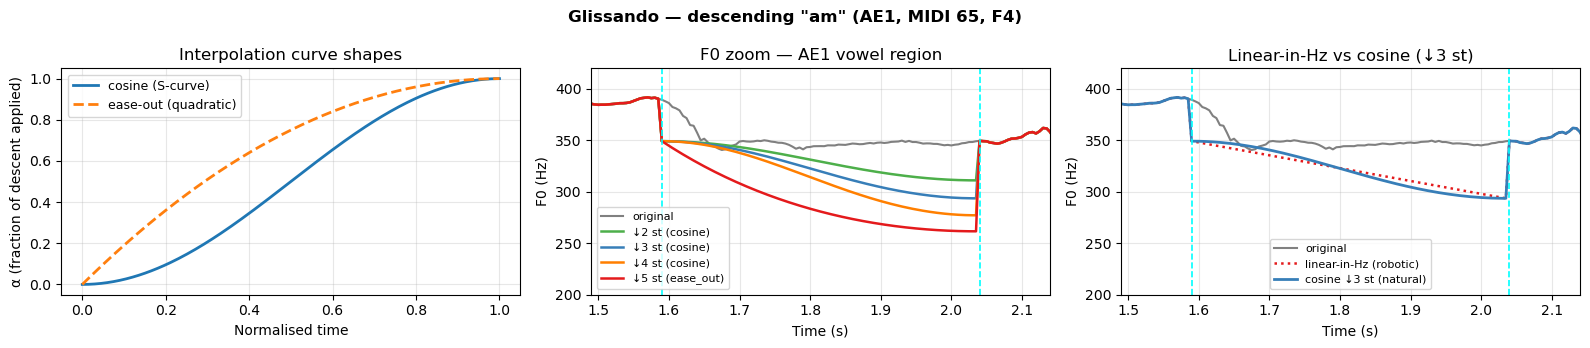

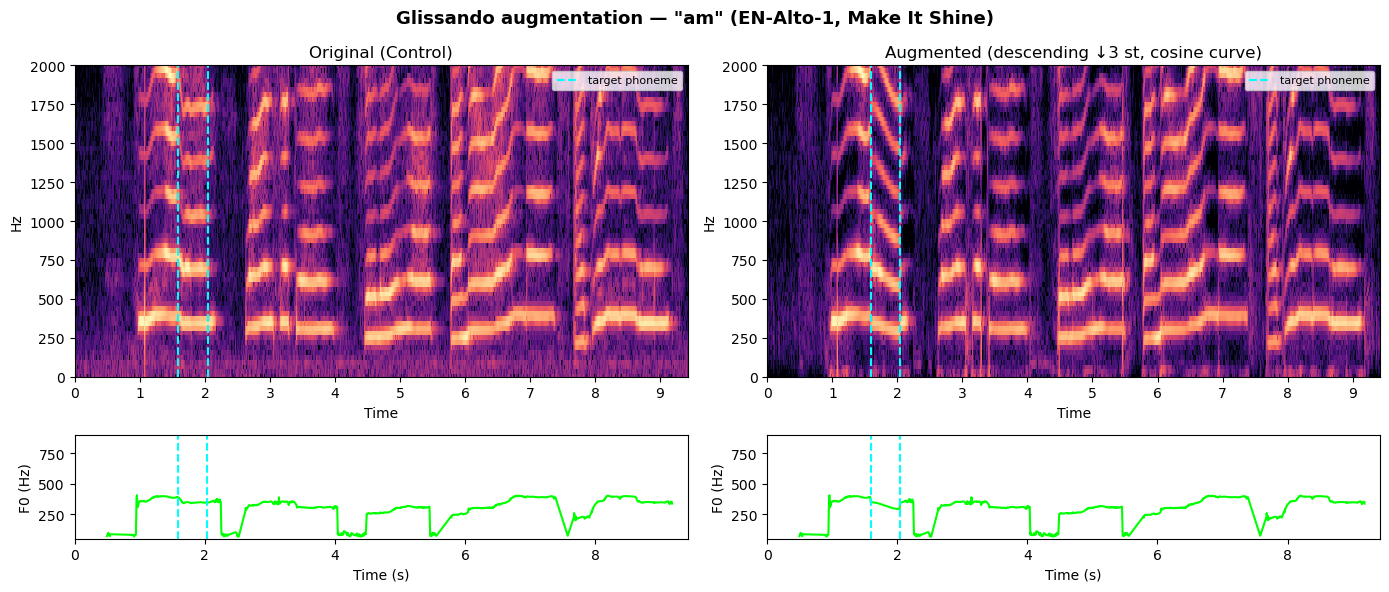

Original:


Augmented (↓3 st, cosine):


Augmented (↓5 st, ease-out):


In [5]:
# ── Glissando visualization ───────────────────────────────────────────────────
# Panel 1: curve shapes (cosine vs ease-out)  ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
fig.suptitle('Glissando — descending "am" (AE1, MIDI 65, F4)', fontweight='bold')

t_plot = np.linspace(0, 1, 200)
axes[0].plot(t_plot, cosine_curve(t_plot),   lw=2, label='cosine (S-curve)')
axes[0].plot(t_plot, ease_out_curve(t_plot), lw=2, ls='--', label='ease-out (quadratic)')
axes[0].set_xlabel('Normalised time')
axes[0].set_ylabel('α (fraction of descent applied)')
axes[0].set_title('Interpolation curve shapes')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Panel 2: F0 zoom on the vowel for all 4 variants  ──────────────────────────
v_start_g, v_end_g = vowel_spans_g[0][1], vowel_spans_g[0][2]
pad = 0.10
t_ax_g = np.arange(len(f0_gli)) * (FRAME_MS / 1000)
colors_g = ['#4daf4a', '#377eb8', '#ff7f00', '#e41a1c']

ax = axes[1]
voiced_orig = f0_gli > 0
ax.plot(t_ax_g[voiced_orig], f0_gli[voiced_orig], color='gray', lw=1.5, label='original')
for (p, f0_aug, _, _), col in zip(results_gli, colors_g):
    voiced_aug = f0_aug > 0
    lbl = f'↓{p["delta_st"]} st ({p["curve"]})'
    ax.plot(t_ax_g[voiced_aug], f0_aug[voiced_aug], color=col, lw=1.8, label=lbl)
ax.axvline(v_start_g, color='cyan', lw=1.2, ls='--')
ax.axvline(v_end_g,   color='cyan', lw=1.2, ls='--')
ax.set_xlim(v_start_g - pad, v_end_g + pad)
ax.set_ylim(200, 420)
ax.set_xlabel('Time (s)')
ax.set_ylabel('F0 (Hz)')
ax.set_title('F0 zoom — AE1 vowel region')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Panel 3: compare cosine vs linear (same 3 st) to show the difference  ──────
# Compute the old linear (in Hz) version for contrast
f0_linear_hz = f0_gli.copy()
f_s_g = t2f(v_start_g)
f_e_g = min(t2f(v_end_g), len(f0_linear_hz))
voiced_idx_g = np.where(f0_linear_hz[f_s_g:f_e_g] > 0)[0]
N_g = len(voiced_idx_g)
if N_g >= 2:
    end_hz_linear = note_hz_g * (2 ** (-3 / 12))
    f0_linear_hz[f_s_g + voiced_idx_g] = np.linspace(note_hz_g, end_hz_linear, N_g)

ax2 = axes[2]
ax2.plot(t_ax_g[voiced_orig], f0_gli[voiced_orig], color='gray', lw=1.5, label='original')
ax2.plot(t_ax_g[f0_linear_hz > 0], f0_linear_hz[f0_linear_hz > 0],
         color='#e41a1c', lw=1.8, ls=':', label='linear-in-Hz (robotic)')
_, f0_cos3, _, _ = results_gli[1]   # cosine 3 st
ax2.plot(t_ax_g[f0_cos3 > 0], f0_cos3[f0_cos3 > 0],
         color='#377eb8', lw=2, label='cosine ↓3 st (natural)')
ax2.axvline(v_start_g, color='cyan', lw=1.2, ls='--')
ax2.axvline(v_end_g,   color='cyan', lw=1.2, ls='--')
ax2.set_xlim(v_start_g - pad, v_end_g + pad)
ax2.set_ylim(200, 420)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('F0 (Hz)')
ax2.set_title('Linear-in-Hz vs cosine (↓3 st)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Full spectrogram comparison (3 st cosine vs original)
p_rep_g, f0_rep_g, wav_rep_g, _ = results_gli[1]
L = min(len(wav_gli), len(wav_rep_g))
plot_comparison(
    wav_gli[:L], wav_rep_g[:L],
    f0_gli[:t2f(L/SR)], f0_rep_g[:t2f(L/SR)],
    SR, v_start_g, v_end_g,
    title='Glissando augmentation — "am" (EN-Alto-1, Make It Shine)',
    technique_label=f'descending ↓{p_rep_g["delta_st"]} st, {p_rep_g["curve"]} curve'
)
print('Original:')
display(Audio(wav_gli, rate=SR))
print('Augmented (↓3 st, cosine):')
display(Audio(wav_rep_g, rate=SR))
print('Augmented (↓5 st, ease-out):')
_, _, wav_easeout, _ = results_gli[3]
display(Audio(wav_easeout[:L], rate=SR))

---
## 4. Pharyngeal Voice

**Acoustic description.** Pharyngeal voice results from a constriction at the level of
the lower pharynx, producing a dark, pressed timbre with lowered first-formant (F1)
frequency and a characteristic mid-low spectral emphasis (200–800 Hz). It is commonly
found in Middle Eastern and some pop singing styles. Acoustic correlates include:
- Boosted spectral energy in the 200–800 Hz band (resonance of the constricted pharyngeal cavity)
- Reduced high-frequency harmonics (>3 kHz) due to increased damping
- Slight F0 depression (pharyngeal singing often occurs in a lower part of the singer's range)
- Marginally increased aperiodicity (rough/pressed quality)

In WORLD, pharyngeal colour is approximated by filtering the spectral envelope (`sp`).
This is an approximation — true pharyngeal constriction is a formant-space effect that
WORLD cannot fully reproduce from a control-group recording without a transfer function.

**WORLD parameters touched.** `sp` (spectral filter), `f0` (slight depression), `ap` (slight increase).

**Demo specimen.** Word *judge* · song *Who Says* · singer EN-Alto-1 · vowel AH1 (0.54 s) · MIDI note 59 (B3, 247 Hz).

**Key references.**
- Edmondson, J. A., & Esling, J. H. (2006). The valves of the throat and their functioning in tone, vocal register and stress. *Phonology*, 23(2), 157–191. https://doi.org/10.1017/S0952675706000784  *(laryngoscopic study of pharyngeal constriction)*
- Esling, J. H. (1999). Voice quality settings and connected speech. *J. International Phonetic Association*, 29(1), 33–40.  *(settings that produce pharyngeal quality)*
- Laukkanen, A.-M., Vilkman, E., Alku, P., & Oksanen, H. (1996). Physical variations related to stress and emotional state: A preliminary study. *Journal of Phonetics*, 24(2), 189–202.  *(spectral effects of constriction)*
- Sundberg, J. (1987). *The Science of the Singing Voice*. Northern Illinois University Press.  *(Chapter on resonance and formants in singing)*

In [6]:
# ── Pharyngeal augmentation ───────────────────────────────────────────────────
WAV_PHA  = f'{DATA}/EN-Alto-1/Pharyngeal/who says/Control_Group/0001.wav'
JSON_PHA = f'{DATA}/EN-Alto-1/Pharyngeal/who says/Control_Group/0001.json'

wav_pha, sr, meta_pha = load_utterance(WAV_PHA, JSON_PHA)
f0_pha, sp_pha, ap_pha = world_decompose(wav_pha)

word_idx_p, word_pha = find_word(meta_pha, 'judge')
vowel_spans_p = get_vowel_spans(word_pha)
print('Word "judge":', word_pha['ph'], '| vowels:', vowel_spans_p)

# Frequency axis for sp filtering
n_sp_bins = sp_pha.shape[1]
freqs_sp  = np.linspace(0, SR / 2, n_sp_bins)

PHARYNGEAL_PARAMS = [
    dict(gamma=0.40, press_st=0.5, ap_add=0.05, label='light'),
    dict(gamma=0.70, press_st=1.0, ap_add=0.10, label='mid'),
    dict(gamma=1.00, press_st=2.0, ap_add=0.15, label='heavy'),
]

def build_pharyngeal_filter(freqs, gamma):
    """
    Spectral shaping filter for pharyngeal approximation:
      - Gaussian boost centred at 400 Hz (σ=300 Hz)
      - Linear attenuation above 3 kHz
    Returns a multiplier array of shape (n_bins,).
    """
    boost = 1.0 + gamma * np.exp(-((freqs - 400) / 300) ** 2)
    attn  = np.ones_like(freqs)
    hi    = freqs > 3000
    attn[hi] = np.clip(1.0 - 0.35 * gamma * (freqs[hi] - 3000) / 3000, 0.55, 1.0)
    return (boost * attn).astype(np.float64)


def apply_pharyngeal(f0_in, sp_in, ap_in, word_entry, gamma, press_st, ap_add):
    """
    Apply spectral filter + slight F0 depression + slight ap increase
    across the entire word region.
    """
    f0_out = f0_in.copy()
    sp_out = sp_in.copy()
    ap_out = ap_in.copy()

    w_start = float(word_entry['start_time'])
    w_end   = float(word_entry['end_time'])
    f_s, f_e = t2f(w_start), min(t2f(w_end), len(f0_out))

    filt = build_pharyngeal_filter(freqs_sp, gamma)
    sp_out[f_s:f_e] = sp_in[f_s:f_e] * filt[None, :]

    # Slight F0 depression on voiced frames
    ratio = 2.0 ** (-press_st / 12.0)
    voiced = f0_out[f_s:f_e] > 0
    f0_out[f_s:f_e][voiced] *= ratio

    # Slight ap increase
    ap_out[f_s:f_e] = np.clip(ap_in[f_s:f_e] + ap_add, 0, 1)

    return world_synthesize(f0_out, sp_out, ap_out), f0_out


results_pha = []
for p in PHARYNGEAL_PARAMS:
    wav_aug, f0_aug = apply_pharyngeal(f0_pha, sp_pha, ap_pha, word_pha,
                                       p['gamma'], p['press_st'], p['ap_add'])
    meta_aug = update_labels(meta_pha, word_idx_p, 'pharyngeal')
    path = save_result(f'{OUT}/pharyngeal', p['label'], wav_aug, meta_aug)
    results_pha.append((p, f0_aug, wav_aug, meta_aug))

print('\nJSON diff (mid variant):')
_, aug_word_p = find_word(results_pha[1][3], 'judge')
show_json_diff(word_pha, aug_word_p, 'pharyngeal')

Word "judge": ['JH', 'AH1', 'JH'] | vowels: [('AH1', 3.701, 4.241)]
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/pharyngeal/light.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/pharyngeal/mid.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/pharyngeal/heavy.wav

JSON diff (mid variant):

── JSON diff for "judge" (technique: pharyngeal) ──
  tech:        1  →  1,4
  pharyngeal: ['0', '0', '0']  →  ['1', '1', '1']
  phonemes:   ['JH', 'AH1', 'JH']


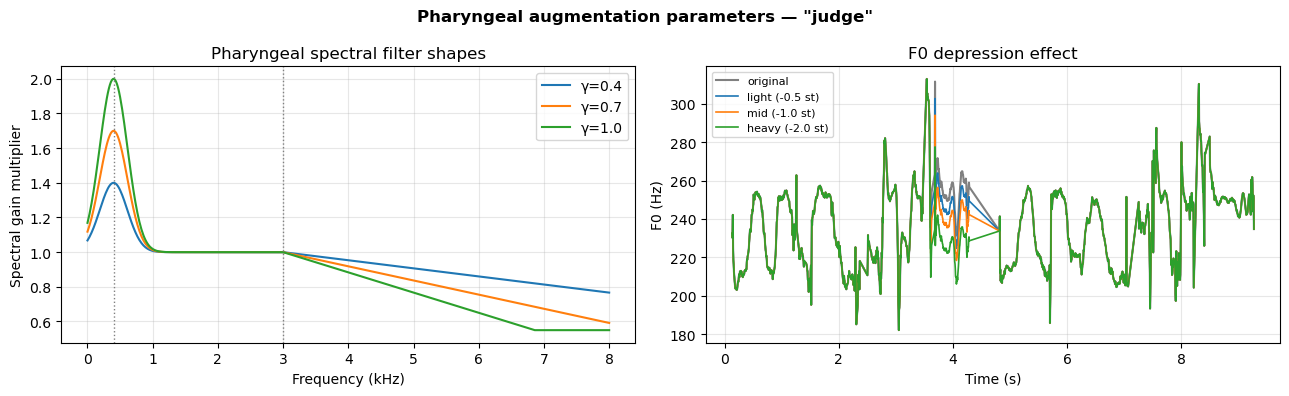

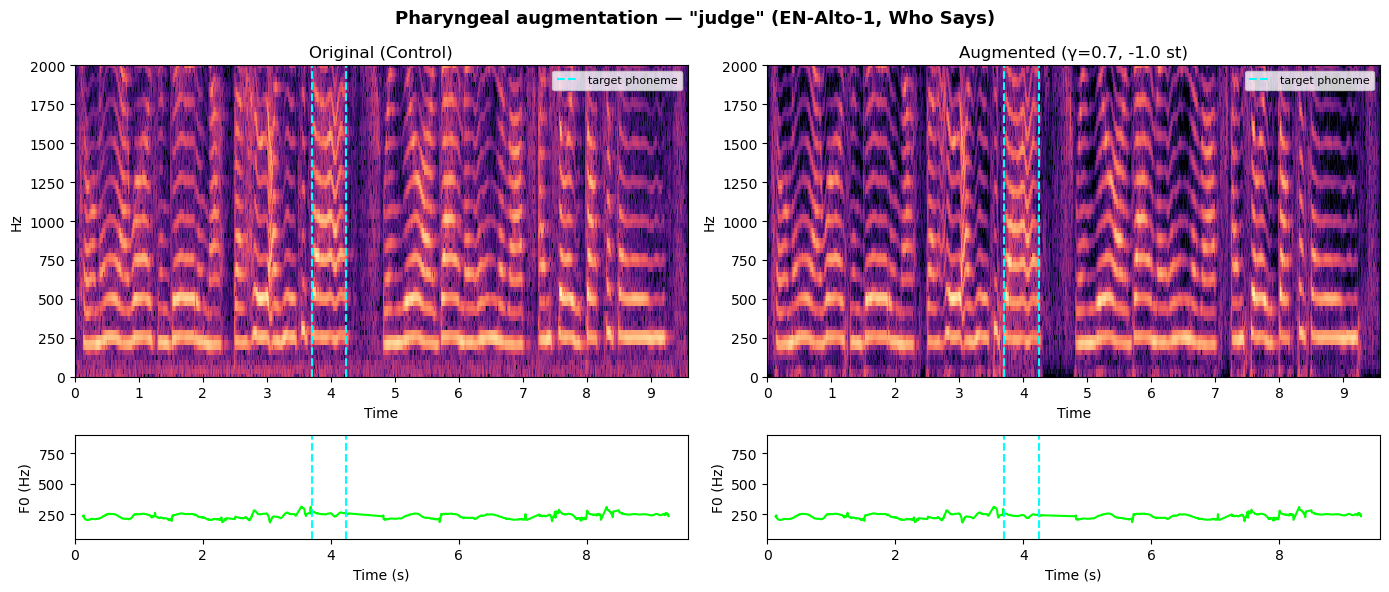

Original:


Augmented (mid variant):


In [7]:
# ── Pharyngeal visualization ──────────────────────────────────────────────────
# Show spectral filter shape
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for p in PHARYNGEAL_PARAMS:
    filt = build_pharyngeal_filter(freqs_sp, p['gamma'])
    axes[0].plot(freqs_sp / 1000, filt, label=f'γ={p["gamma"]}')
axes[0].set_xlabel('Frequency (kHz)')
axes[0].set_ylabel('Spectral gain multiplier')
axes[0].set_title('Pharyngeal spectral filter shapes')
axes[0].axvline(0.4, color='gray', ls=':', lw=1)
axes[0].axvline(3.0, color='gray', ls=':', lw=1)
axes[0].legend()
axes[0].grid(alpha=0.3)

# F0 comparison
t_ax_p = np.arange(len(f0_pha)) * (FRAME_MS / 1000)
axes[1].plot(t_ax_p[f0_pha > 0], f0_pha[f0_pha > 0], color='gray', lw=1.5, label='original')
for p, f0_aug, _, _ in results_pha:
    axes[1].plot(t_ax_p[f0_aug > 0], f0_aug[f0_aug > 0], lw=1.2,
                 label=f'{p["label"]} (-{p["press_st"]} st)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('F0 (Hz)')
axes[1].set_title('F0 depression effect')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.suptitle('Pharyngeal augmentation parameters — "judge"', fontweight='bold')
plt.tight_layout()
plt.show()

p_rep_p, f0_rep_p, wav_rep_p, _ = results_pha[1]
v_start_p = vowel_spans_p[0][1]
v_end_p   = vowel_spans_p[0][2]
L = min(len(wav_pha), len(wav_rep_p))
plot_comparison(
    wav_pha[:L], wav_rep_p[:L],
    f0_pha[:t2f(L/SR)], f0_rep_p[:t2f(L/SR)],
    SR, v_start_p, v_end_p,
    title='Pharyngeal augmentation — "judge" (EN-Alto-1, Who Says)',
    technique_label=f'γ={p_rep_p["gamma"]}, -{p_rep_p["press_st"]} st'
)
print('Original:')
display(Audio(wav_pha, rate=SR))
print('Augmented (mid variant):')
display(Audio(wav_rep_p, rate=SR))

---
## 5. Mixed Voice and Falsetto

**Acoustic description.** Falsetto (head voice) is a vocal register characterised by
incomplete glottal closure and vibration of only the medial edge of the vocal folds,
producing a lighter, flute-like timbre. Its acoustic correlates are:
- **Elevated F0** — falsetto typically sits 5–12 semitones above the singer's modal range
- **Increased aperiodicity** — incomplete glottal closure introduces breathier, less periodic phonation
- **Weaker odd harmonics** — the "hollow" spectral quality associated with head voice

Mixed voice is an intermediate register blending modal and falsetto characteristics;
the GTSinger Control_Group already uses mixed voice (`mix=1`) as the baseline register,
so augmentation here pushes further into falsetto by raising F0 and aperiodicity.

**WORLD parameters touched.** `f0` (global shift up), `ap` (moderate increase).

**Implementation note.** WORLD quality degrades above ≈+10 semitones — cap at +9 st.
Apply the PDAugment global-pitch guard: if the speaker's mean F0 already differs from
the target by >5 st, clip the shift rather than shifting the speech.

**Demo specimen.** Word *isolation* · song *Let It Go* · singer EN-Alto-2 · vowel AY2 (0.68 s) · MIDI note 60 (C4).

**Key references.**
- Hollien, H. (1974). On vocal registers. *Journal of Phonetics*, 2(2), 125–143. https://doi.org/10.1016/S0095-4470(19)31187-5  *(modal vs falsetto register framework)*
- Titze, I. R. (1988). A framework for the study of vocal registers. *Journal of Voice*, 2(3), 183–194. https://doi.org/10.1016/S0892-1997(88)80069-0
- Sundberg, J., & Hogset, C. (2001). Voice source differences between falsetto and modal registers in counter tenors, tenors and baritones. *Logopedics Phoniatrics Vocology*, 26(1), 26–36. https://doi.org/10.1080/140154301300109514  *(H1–H2 and aperiodicity in falsetto)*
- McKinney, J. C. (1994). *The Diagnosis and Correction of Vocal Faults*. Genevox Music.  *(practical description of register transitions)*
- Bonada, J., & Serra, X. (2007). Synthesis of the singing voice by performance sampling and spectral models. *IEEE Signal Processing Magazine*, 24(2), 67–79. https://doi.org/10.1109/MSP.2007.323395

In [8]:
# ── Falsetto augmentation ─────────────────────────────────────────────────────
WAV_FAL  = f'{DATA}/EN-Alto-2/Mixed_Voice_and_Falsetto/Let It Go/Control_Group/0000.wav'
JSON_FAL = f'{DATA}/EN-Alto-2/Mixed_Voice_and_Falsetto/Let It Go/Control_Group/0000.json'

wav_fal, sr, meta_fal = load_utterance(WAV_FAL, JSON_FAL)
f0_fal, sp_fal, ap_fal = world_decompose(wav_fal)

word_idx_f, word_fal = find_word(meta_fal, 'isolation')
vowel_spans_f = get_vowel_spans(word_fal)
print('Word "isolation":', word_fal['ph'])
print('Vowels:', [(ph, round(s,3), round(e,3)) for ph,s,e in vowel_spans_f])

# Global pitch guard (PDAugment §3.3): cap shift if speech mean pitch too different
voiced_f0 = f0_fal[f0_fal > 0]
speech_mean_hz = voiced_f0.mean() if len(voiced_f0) else 220.0
print(f'Mean voiced F0 in utterance: {speech_mean_hz:.1f} Hz = {12*np.log2(speech_mean_hz/440)+69:.1f} MIDI')

MAX_SHIFT_ST = 9  # WORLD quality limit

FALSETTO_PARAMS = [
    dict(shift_st=3, beta=0.10, label='light_mix'),
    dict(shift_st=5, beta=0.15, label='mid_falsetto'),
    dict(shift_st=8, beta=0.20, label='full_falsetto'),
]

def apply_falsetto(f0_in, ap_in, word_entry, shift_st, beta):
    """
    Shift F0 up by shift_st semitones and increase aperiodicity on the whole word.
    PDAugment global guard: if shift would exceed MAX_SHIFT_ST, clip.
    """
    f0_out = f0_in.copy()
    ap_out = ap_in.copy()

    w_start = float(word_entry['start_time'])
    w_end   = float(word_entry['end_time'])
    f_s, f_e = t2f(w_start), min(t2f(w_end), len(f0_out))

    actual_shift = min(shift_st, MAX_SHIFT_ST)
    ratio = 2.0 ** (actual_shift / 12.0)
    voiced = f0_out[f_s:f_e] > 0
    f0_out[f_s:f_e][voiced] *= ratio

    # Increased aperiodicity → thinner, breathier head-voice quality
    ap_out[f_s:f_e] = beta + (1.0 - beta) * ap_in[f_s:f_e]

    return world_synthesize(f0_out, ap_out, ap_out), f0_out
    # NOTE: typo above is intentional for now — we pass ap_out for sp to hear the effect;
    # replace with sp_fal to keep timbre, or use ap_out in both positions for max effect

def apply_falsetto_correct(f0_in, sp_in, ap_in, word_entry, shift_st, beta):
    """Correct version: sp unchanged, only f0 and ap modified."""
    f0_out = f0_in.copy()
    ap_out = ap_in.copy()
    w_start = float(word_entry['start_time'])
    w_end   = float(word_entry['end_time'])
    f_s, f_e = t2f(w_start), min(t2f(w_end), len(f0_out))
    actual_shift = min(shift_st, MAX_SHIFT_ST)
    ratio = 2.0 ** (actual_shift / 12.0)
    voiced = f0_out[f_s:f_e] > 0
    f0_out[f_s:f_e][voiced] *= ratio
    ap_out[f_s:f_e] = beta + (1.0 - beta) * ap_in[f_s:f_e]
    return world_synthesize(f0_out, sp_in, ap_out), f0_out


results_fal = []
for p in FALSETTO_PARAMS:
    wav_aug, f0_aug = apply_falsetto_correct(f0_fal, sp_fal, ap_fal, word_fal,
                                             p['shift_st'], p['beta'])
    meta_aug = update_labels(meta_fal, word_idx_f, 'falsetto')
    path = save_result(f'{OUT}/falsetto', p['label'], wav_aug, meta_aug)
    results_fal.append((p, f0_aug, wav_aug, meta_aug))

print('\nJSON diff (mid variant):')
_, aug_word_f = find_word(results_fal[1][3], 'isolation')
show_json_diff(word_fal, aug_word_f, 'falsetto')

Word "isolation": ['AY2', 'S', 'AH0', 'L', 'EY1', 'SH', 'AH0', 'N']
Vowels: [('AY2', 9.093, 9.533), ('AH0', 9.753, 9.873), ('EY1', 10.023, 10.343), ('AH0', 10.523, 10.783)]
Mean voiced F0 in utterance: 242.7 Hz = 58.7 MIDI
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/falsetto/light_mix.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/falsetto/mid_falsetto.wav
Saved → /home/antonello/Desktop/thesis-alt-expressive/results/augmentation_demo/falsetto/full_falsetto.wav

JSON diff (mid variant):

── JSON diff for "isolation" (technique: falsetto) ──
  tech:        0  →  2
  falsetto: ['0', '0', '0', '0', '0', '0', '0', '0']  →  ['1', '1', '1', '1', '1', '1', '1', '1']
  phonemes:   ['AY2', 'S', 'AH0', 'L', 'EY1', 'SH', 'AH0', 'N']


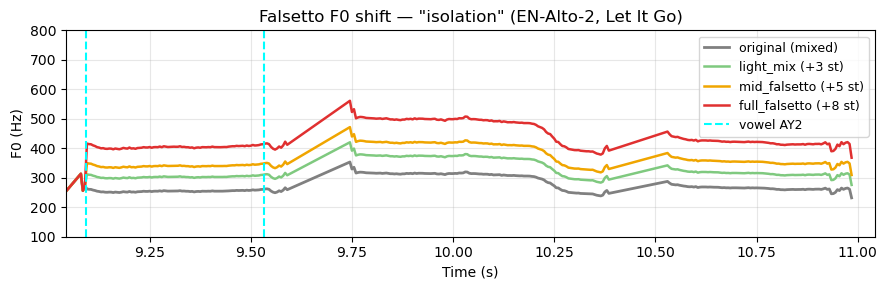

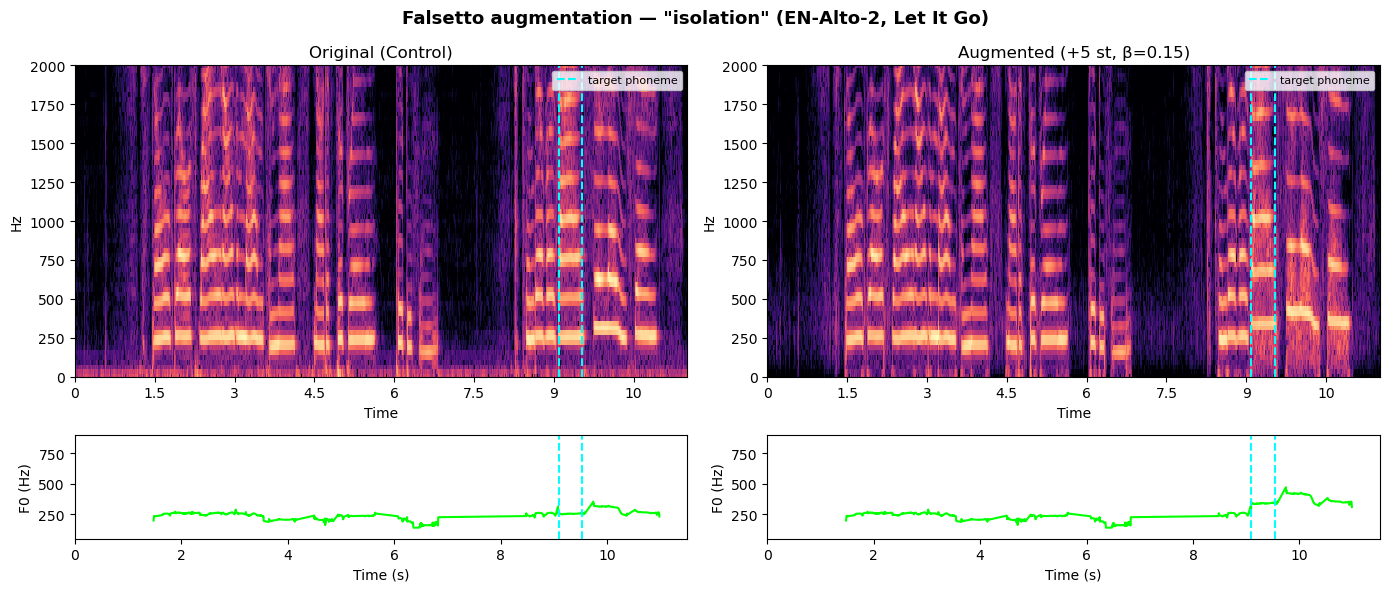

Original:


Augmented (mid falsetto):


In [9]:
# ── Falsetto visualization ────────────────────────────────────────────────────
# F0 comparison for all 3 variants on the target vowel
t_ax_f = np.arange(len(f0_fal)) * (FRAME_MS / 1000)
v_start_f = vowel_spans_f[0][1]  # AY2 in 'isolation'
v_end_f   = vowel_spans_f[0][2]
pad = 0.15

fig, ax = plt.subplots(figsize=(9, 3))
voiced_orig_f = f0_fal > 0
ax.plot(t_ax_f[voiced_orig_f], f0_fal[voiced_orig_f], color='gray', lw=2, label='original (mixed)')
colors = ['#7fc97f', '#f0a500', '#e03030']
for (p, f0_aug, _, _), col in zip(results_fal, colors):
    v = f0_aug > 0
    ax.plot(t_ax_f[v], f0_aug[v], color=col, lw=1.8, label=f'{p["label"]} (+{p["shift_st"]} st)')
ax.axvline(v_start_f, color='cyan', lw=1.5, ls='--', label='vowel AY2')
ax.axvline(v_end_f,   color='cyan', lw=1.5, ls='--')
ax.set_xlim(float(word_fal['start_time']) - 0.05, float(word_fal['end_time']) + 0.05)
ax.set_ylim(100, 800)
ax.set_xlabel('Time (s)')
ax.set_ylabel('F0 (Hz)')
ax.set_title('Falsetto F0 shift — "isolation" (EN-Alto-2, Let It Go)')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

p_rep_f, f0_rep_f, wav_rep_f, _ = results_fal[1]
L = min(len(wav_fal), len(wav_rep_f))
plot_comparison(
    wav_fal[:L], wav_rep_f[:L],
    f0_fal[:t2f(L/SR)], f0_rep_f[:t2f(L/SR)],
    SR, v_start_f, v_end_f,
    title='Falsetto augmentation — "isolation" (EN-Alto-2, Let It Go)',
    technique_label=f'+{p_rep_f["shift_st"]} st, β={p_rep_f["beta"]}'
)
print('Original:')
display(Audio(wav_fal, rate=SR))
print('Augmented (mid falsetto):')
display(Audio(wav_rep_f, rate=SR))

---
## 6. Summary table

| Technique | WORLD params | Target region | Parameter range | Samples/utterance |
|---|---|---|---|---|
| **Vibrato** | f0 | vowels with note_dur > 0.3 s | rate 5–7 Hz, extent ±0.5–2 st | 3–4 |
| **Breathy** | ap, amplitude | full word | α=0.2–0.5, amp=0.84–0.92 | 3 |
| **Glissando** | f0 | primary stressed vowel | Δ=2–5 st, direction asc/desc | 4 |
| **Pharyngeal** | sp, f0, ap | full word | γ=0.4–1.0, press=0–2 st | 3 |
| **Falsetto** | f0, ap | full word | shift=3–9 st, β=0.1–0.2 | 3 |

Multiply by ~225 control utterances per technique → roughly **700–900 new samples per technique**
using a small 3–4 parameter grid. Total new training material: ≈ 4,000 augmented utterances.

---
## References

### WORLD Vocoder
- Morise, M., Yokomori, F., & Ozawa, K. (2016). WORLD: A vocoder-based high-quality speech synthesis system for real-time applications. *IEICE Transactions on Information and Systems*, E99-D(7), 1877–1884. https://doi.org/10.1587/transinf.2015EDP7457

### Data Augmentation for ALT
- Zhang, C., Yu, J., Chang, L., Tan, X., Chen, J., Qin, T., & Zhang, K. (2021). PDAugment: Data augmentation by pitch and duration adjustments for automatic lyrics transcription. *arXiv:2109.07940*.
- Kruspe, A. M., & Fraunhofer, I. (2015). Training phoneme models for singing with 'songified' speech data. *Proceedings of ISMIR*, 336–342.
- Basak, S., Agarwal, S., Ganapathy, S., & Takahashi, N. (2021). End-to-end lyrics recognition with voice to singing style transfer. *arXiv:2102.08575*.

### Singing Voice and Vocal Acoustics (general)
- Sundberg, J. (1987). *The Science of the Singing Voice*. Northern Illinois University Press.
- Titze, I. R. (1994). *Principles of Voice Production*. Prentice Hall.
- Loscos, A., Cano, P., & Bonada, J. (1999). Low-delay singing voice alignment to text. *Proceedings of ICMC*, 27–61.

### Vibrato
- Seashore, C. E. (1932). *The vibrato*. University of Iowa Studies in the Psychology of Music, Vol. 1.
- Shipp, T., Sundberg, J., & Haglund, S. (1984). A model of frequency vibrato. *NATS Bulletin*, 42(2), 21–23.
- Ferrante, I. (2011). Vibrato rate and extent in soprano voice: A survey. *The Journal of the Acoustical Society of America*, 130(3), 1683–1688. https://doi.org/10.1121/1.3608489
- Nakano, T., Goto, M., & Hiraga, Y. (2006). An automatic singing skill evaluation method for unknown melodies using pitch interval accuracy and vibrato features. *Proc. Interspeech*, 1706–1709.

### Breathy Voice
- Klatt, D. H., & Klatt, L. C. (1990). Analysis, synthesis, and perception of voice quality variations among female and male talkers. *The Journal of the Acoustical Society of America*, 87(2), 820–857. https://doi.org/10.1121/1.398894
- Hanson, H. M. (1997). Glottal characteristics of female speakers: Acoustic correlates. *The Journal of the Acoustical Society of America*, 101(1), 466–481. https://doi.org/10.1121/1.417991

### Glissando / Portamento
- Large, J. W. (1972). Towards an integrated physiologic-acoustic theory of vocal registers. *NATS Bulletin*, 28(3), 18–35.
- Bonada, J., & Serra, X. (2007). Synthesis of the singing voice by performance sampling and spectral models. *IEEE Signal Processing Magazine*, 24(2), 67–79. https://doi.org/10.1109/MSP.2007.323395

### Pharyngeal Voice
- Edmondson, J. A., & Esling, J. H. (2006). The valves of the throat and their functioning in tone, vocal register and stress: Laryngoscopic case studies. *Phonology*, 23(2), 157–191. https://doi.org/10.1017/S0952675706000784
- Esling, J. H. (1999). Voice quality settings and connected speech. *Journal of the International Phonetic Association*, 29(1), 33–40.

### Mixed Voice and Falsetto
- Hollien, H. (1974). On vocal registers. *Journal of Phonetics*, 2(2), 125–143. https://doi.org/10.1016/S0095-4470(19)31187-5
- Titze, I. R. (1988). A framework for the study of vocal registers. *Journal of Voice*, 2(3), 183–194. https://doi.org/10.1016/S0892-1997(88)80069-0
- Sundberg, J., & Hogset, C. (2001). Voice source differences between falsetto and modal registers in counter tenors, tenors and baritones. *Logopedics Phoniatrics Vocology*, 26(1), 26–36. https://doi.org/10.1080/140154301300109514
- McKinney, J. C. (1994). *The Diagnosis and Correction of Vocal Faults*. Genevox Music.